In [16]:
import pandas as pd
data ={ "Month":["Jan","Feb","Mar","Apr"],
       "Revenue":[50000, 65000,60000,85000]
        }
df= pd.DataFrame(data)
print(df)

  Month  Revenue
0   Jan    50000
1   Feb    65000
2   Mar    60000
3   Apr    85000


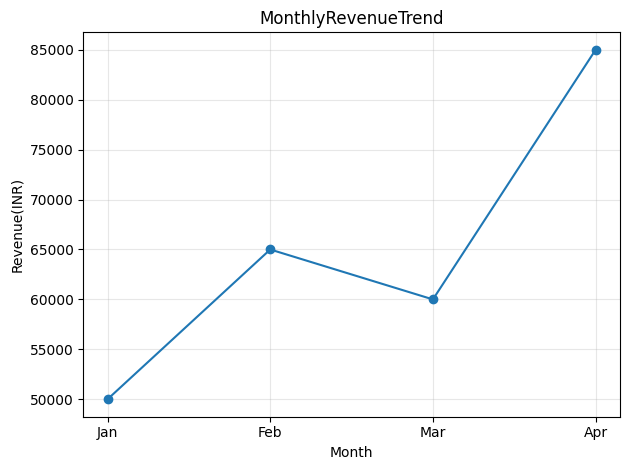

In [19]:
import matplotlib.pyplot as plt
plt.plot(
    df["Month"],
    df["Revenue"],
    marker="o" )
plt.title("MonthlyRevenueTrend")
plt.xlabel("Month")
plt.ylabel("Revenue(INR)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


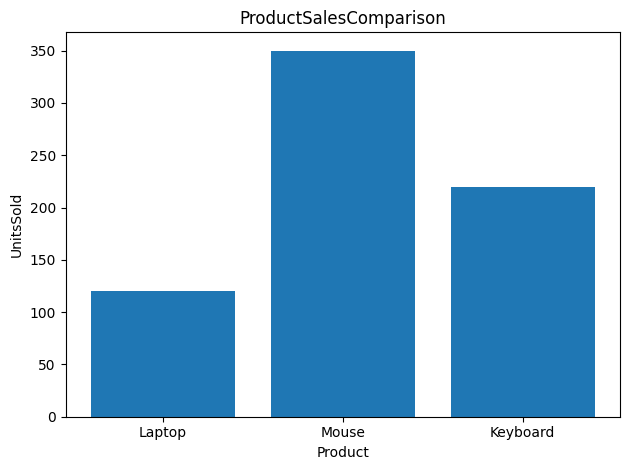

In [20]:
products=["Laptop","Mouse","Keyboard"]
sales=[120,350,220]
plt.bar(products,sales)
plt.title("ProductSalesComparison")
plt.xlabel("Product")
plt.ylabel("UnitsSold")
plt.tight_layout()
plt.show()

In [21]:
df["Growth_Percent"]= (
     df["Revenue"].pct_change()*100
     )
print(df)

  Month  Revenue  Growth_Percent
0   Jan    50000             NaN
1   Feb    65000       30.000000
2   Mar    60000       -7.692308
3   Apr    85000       41.666667


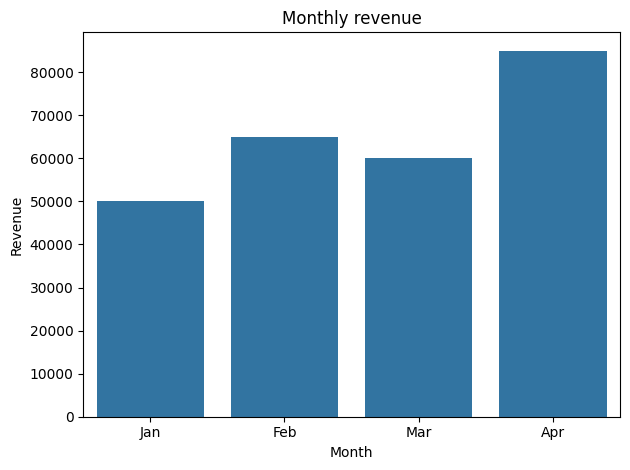

In [23]:
import seaborn as sns

sns.barplot(
    data=df,
    x="Month",
    y="Revenue",
    errorbar=None
)

plt.title("Monthly revenue")
plt.tight_layout()
plt.show()

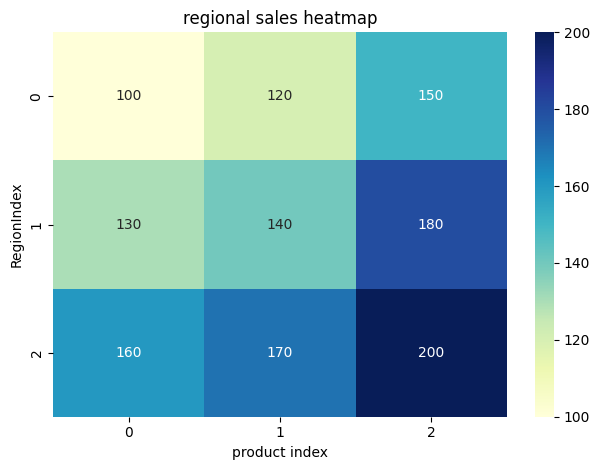

In [25]:
import numpy as np

sales=np.array([
    [100,120,150],
    [130,140,180],
    [160,170,200]
])

sna.heatmap(
    sales,
    annot=True,
    fmt="d",
    cmap="YlGnBu"
    )
plt.title("regional sales heatmap")
plt.xlabel("product index")
plt.ylabel("RegionIndex")
plt.tight_layout()
plt.show()

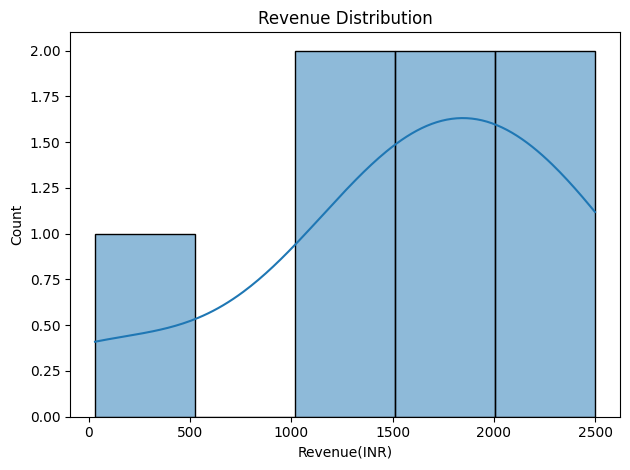

In [28]:
revenue=[ 1200,1500,1700,2000, 2200,2500,30]

sns.histplot(
    revenue,
    bins=5,
    kde=True
)

plt.title("Revenue Distribution")
plt.xlabel("Revenue(INR)")
plt.tight_layout()
plt.show()


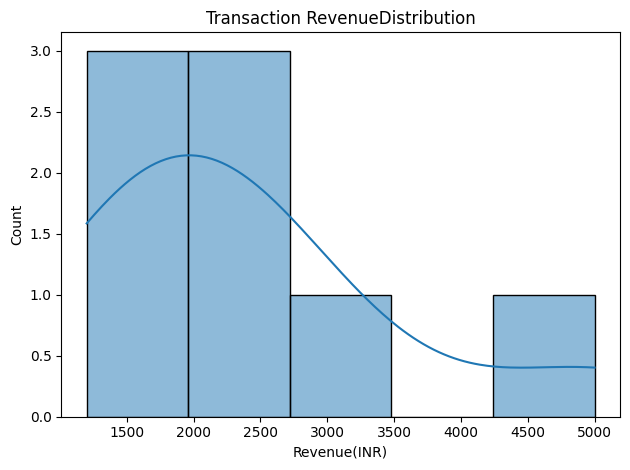

In [29]:
revenue=[ 1200,1500,1700,2000, 2200,2500,3000,5000 ]
sns.histplot( revenue, bins=5, kde=True )
plt.title("Transaction RevenueDistribution")
plt.xlabel("Revenue(INR)")
plt.tight_layout()
plt.show()

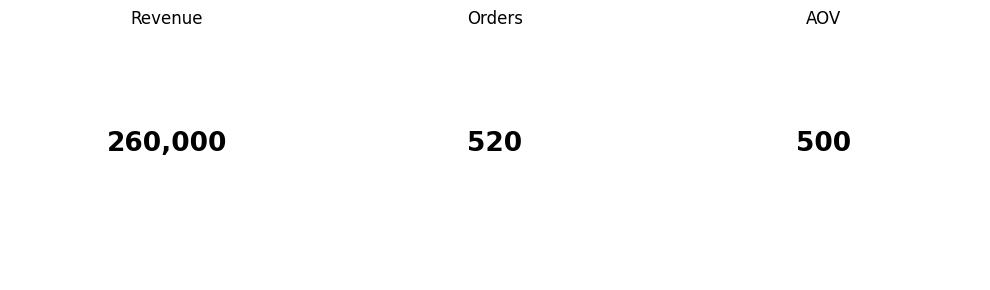

In [30]:
import matplotlib.pyplot as plt
metrics={ "Revenue":260000, "Orders":520, "AOV":500 }
fig, axes=plt.subplots(1,3,figsize=(10,3))
for ax,(name,value) in zip( axes,metrics.items() ):
  ax.text( 0.5,0.55,f"{value:,.0f}", ha="center",va="center", fontsize=19,weight="bold" )
  ax.set_title(name)
  ax.axis("off")
plt.tight_layout()
plt.show()

SALESDASHBOARD
Revenue: 193500
Orders: 8
AOV: 24187.5


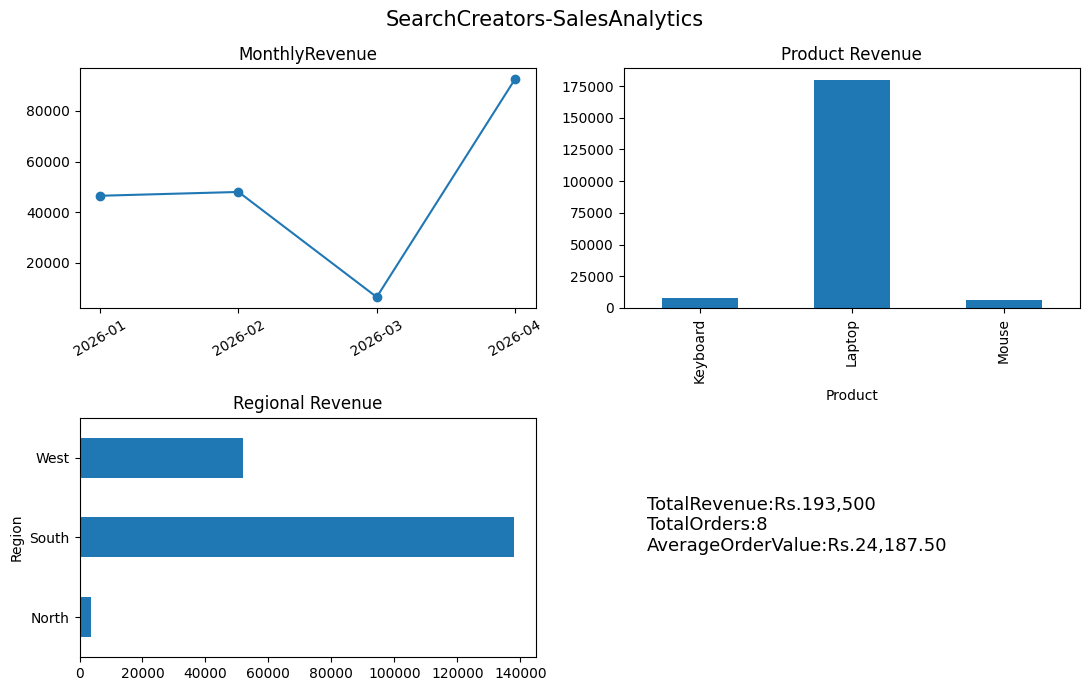

In [19]:
import pandas as pd
import matplotlib.pyplot as plt
data ={ "Order_ID":[
    1,2,3, 4, 5, 6,7,8 ],
        "Date":[ "2026-01-05","2026-01-12",
                "2026-02-08","2026-02-20",
                 "2026-03-02","2026-03-15",
                 "2026-04-04","2026-04-18" ],
        "Product":[
            "Laptop","Mouse","Keyboard",
            "Laptop","Mouse","Keyboard",
            "Laptop","Mouse"],
        "Region":[
            "South","North","South",
            "West","North","West",
            "South","West"],
        "Quantity":[ 1,3,2, 1, 4, 3,2,5],

        "Unit_Price": [ 45000,500,1500,45000, 500,1500,45000,500 ]
        }
df= pd.DataFrame(data)

df["Date"]=pd.to_datetime(df["Date"])
df["Revenue"] =( df["Quantity"] *df["Unit_Price"] )
df["Month"] =( df["Date"].dt.to_period("M").astype(str) )

total_revenue =df["Revenue"].sum()
total_orders =df["Order_ID"].nunique()
aov=total_revenue/total_orders

monthly=df.groupby( "Month" )["Revenue"].sum()

product=df.groupby( "Product" )["Revenue"].sum()

region=df.groupby( "Region" )["Revenue"].sum()

print("SALESDASHBOARD")
print("Revenue:", total_revenue)
print("Orders:", total_orders)
print("AOV:", round(aov,2))

fig, axes=plt.subplots( 2,2,figsize=(11, 7) )

axes[0,0].plot( monthly.index, monthly.values, marker="o" )
axes[0,0].set_title("MonthlyRevenue")
axes[0,0].tick_params( axis="x",rotation=30 )

product.plot( kind="bar", ax=axes[0,1], title="Product Revenue" )

region.plot( kind="barh", ax=axes[1,0], title="Regional Revenue" )

axes[1,1].axis("off")

kpi_text=(
    f"TotalRevenue:Rs.{total_revenue:,.0f}\n"
    f"TotalOrders:{total_orders}\n"
    f"AverageOrderValue:Rs.{aov:,.2f}" )
axes[1,1].text( 0.05,0.55, kpi_text, fontsize=13, va="center" )

fig.suptitle( "SearchCreators-SalesAnalytics", fontsize=15 )

plt.tight_layout()

plt.savefig( "sales_dashboard.png", dpi=180, bbox_inches="tight" )

plt.show()
df.to_csv( "sales_analysis.csv", index=False )